# creapy library tutorial: from a fixation table to figures and statistics

This notebook walks through the `creapy` library (no GUI): load a table, build per-stimulus datasets, draw
heatmaps and scanpaths, define areas of interest, compute descriptives, compare groups, measure scanpath
similarity, rhythm and recurrence. Everything the desktop app `creapy.io` shows is produced by these functions.

It runs on the **synthetic example dataset** (twelve invented viewers, two generated pictures), so no participant
data is needed. Replace the path with your own EyeLink fixation report or Tobii Pro Lab export.

In [1]:
import matplotlib.pyplot as plt
import creapy
from creapy.examples import example_dataset

path = example_dataset()            # -> .../creapy/examples/demo_fixations.csv (generated on first call)
df, mapping = creapy.load_fixations(path)
print(df.head())
print(mapping)

  participant   group  age  trial               image  t_start    dur      x  \
0         P01  expert   25      1  demo_picture_A.png     50.0  260.1  821.7   
1         P01  expert   25      1  demo_picture_A.png    366.7  203.4  850.5   
2         P01  expert   25      1  demo_picture_A.png    613.2  198.7  744.7   
3         P01  expert   25      1  demo_picture_A.png    855.3  492.4  664.4   
4         P01  expert   25      1  demo_picture_A.png   1393.5  217.4  709.2   

       y  pupil  
0  429.3  888.3  
1  449.9  896.6  
2  563.7  845.0  
3  463.6  871.5  
4  351.4  954.1  
{'stim_col': 'image', 'subj_index_col': 'participant', 'fix_t_col': 't_start', 'fix_dur_col': 'dur', 'fix_x_col': 'x', 'fix_y_col': 'y', 'trial_col': 'trial', 'pupil_col': 'pupil'}


`load_fixations` reads CSV/TSV/Excel (any delimiter, decimal commas, EyeLink `.` missing values) and guesses the
column mapping; Tobii Pro Lab exports (event-based metrics export or Data export) are converted to one row per
fixation on the way. Correct a guess by passing `mapping=` or keyword arguments, e.g.
`creapy.load_fixations(path, fix_x_col='CURRENT_FIX_X')`.

In [2]:
import os
folder = os.path.dirname(path)
# the example table holds bare file names; give datasets_by_stimulus the folder with the images (or a dict name -> path)
datasets = creapy.datasets_by_stimulus(df, mapping, stimulus_paths=folder)   # {stimulus -> (FixationData, SaccadeData)}
fix, sac = datasets['demo_picture_A.png']
print(fix.n_subjects(), "participants,", len(fix.df), "fixations,", len(sac.df), "saccades;",
      "image", fix.width, "x", fix.height, "px; durations in", fix.dur_unit)


12 participants, 1061 fixations, 1049 saccades; image 1600 x 1200 px; durations in ms


## Heatmap, scanpath, saccades

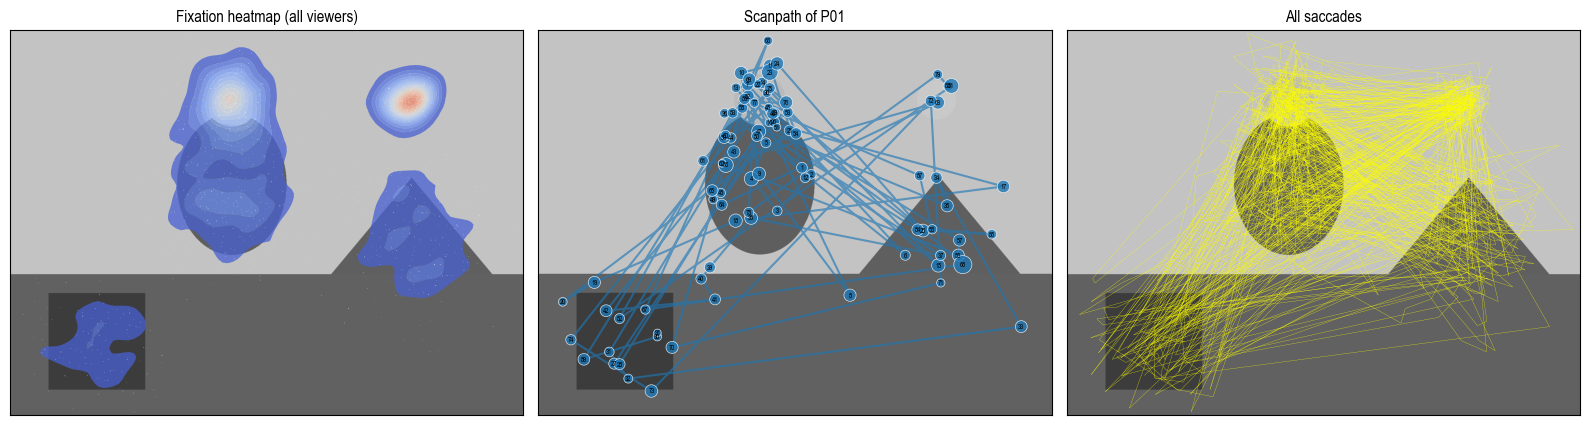

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
fix.make_heatmap(axes[0], bw_method=0.1, cmap='coolwarm', grayscale=True)
fix.visualize_scanpath(axes[1], subjects=[fix.subjects[0]], grayscale=True)
sac.visualize_scanpaths(axes[2], grayscale=True)
for ax, title in zip(axes, ["Fixation heatmap (all viewers)", f"Scanpath of {fix.subjects[0]}", "All saccades"]):
    ax.set_title(title)
fig.tight_layout()

**Same colour scale across pictures.** By default every heatmap is scaled to its own peak. To compare two
heatmaps by colour, take the maximum density of one dataset and pass it as `vmax` to all of them.

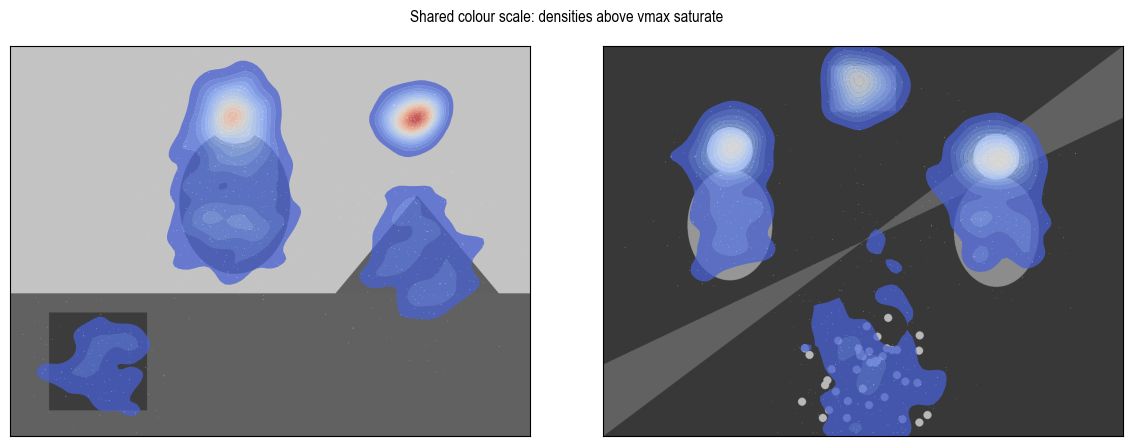

In [4]:
fix_b, sac_b = datasets['demo_picture_B.png']
vmax = max(fix.heatmap_max(bw_method=0.1), fix_b.heatmap_max(bw_method=0.1))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
fix.make_heatmap(axes[0], bw_method=0.1, vmax=vmax, grayscale=True)
fix_b.make_heatmap(axes[1], bw_method=0.1, vmax=vmax, grayscale=True)
fig.suptitle("Shared colour scale: densities above vmax saturate")
fig.tight_layout()

## Subsets: participants, groups, time windows

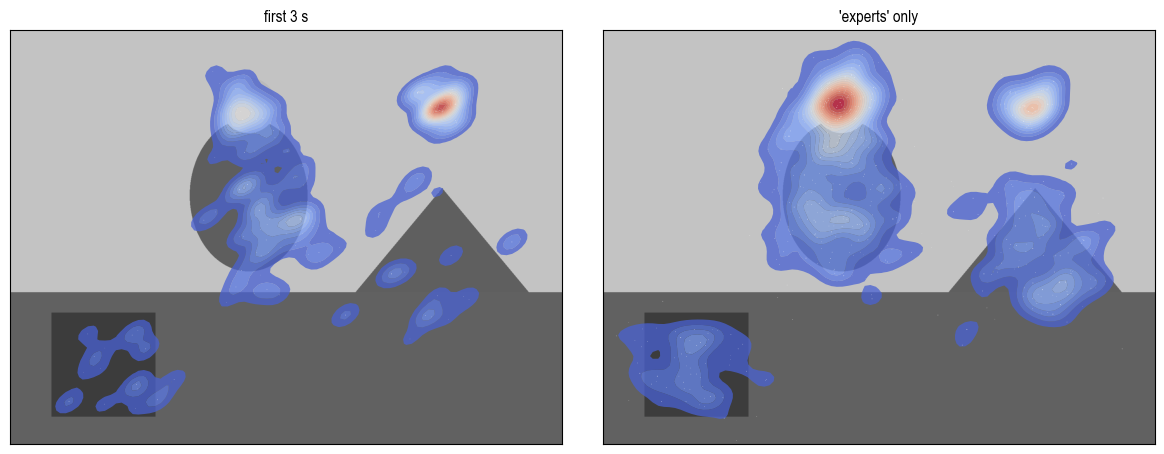

In [5]:
early = fix.subset(t_range=(0, 3))            # the first three seconds of everyone
experts = fix.subset(subjects=[s for s in fix.subjects if s <= 'P06'])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
early.make_heatmap(axes[0], grayscale=True); axes[0].set_title("first 3 s")
experts.make_heatmap(axes[1], grayscale=True); axes[1].set_title("'experts' only")
fig.tight_layout()

## Areas of interest: metrics, sequences, transitions

In [6]:
fix.set_top_down_aoi('head', creapy.AOI.rectangle('head', 560, 100, 820, 320).geom)
fix.set_top_down_aoi('object', creapy.AOI.rectangle('object', 1150, 130, 1330, 310).geom)
fix.set_top_down_aoi('block', creapy.AOI.polygon('block', [(100, 800), (440, 800), (440, 1140), (100, 1140)]).geom)
df_aoi = fix.aoi_metrics()         # participant x AOI: n_fixations, dwell_time, dwell_share, n_visits, revisits, ...
df_aoi.head(6)

,participant,aoi,n_fixations,n_visits,revisits,dwell_time,dwell_share,mean_fixation_duration,time_to_first_fixation,first_fixation_rank,aoi_area_share
0,P01,head,27,15,14,7639.9,0.294245,282.959259,1.8555,7,0.029792
1,P02,head,28,14,13,7466.0,0.287054,266.642857,2.6743,8,0.029792
2,P03,head,11,9,8,3492.0,0.156340,317.454545,1.1640,6,0.029792
3,P04,head,27,10,9,7207.7,0.274857,266.951852,1.3063,6,0.029792
4,P05,head,17,14,13,4903.2,0.197483,288.423529,1.8848,8,0.029792
5,P06,head,19,11,10,4637.4,0.210913,244.073684,1.0781,5,0.029792


,participant,head,object,block
0,P01,1,3,2
1,P02,2,1,3
2,P03,2,1,3
3,P04,2,3,1
4,P05,3,1,2
5,P06,1,2,3
6,P07,2,1,3
7,P08,1,2,3
8,P09,3,2,1
9,P10,1,3,2


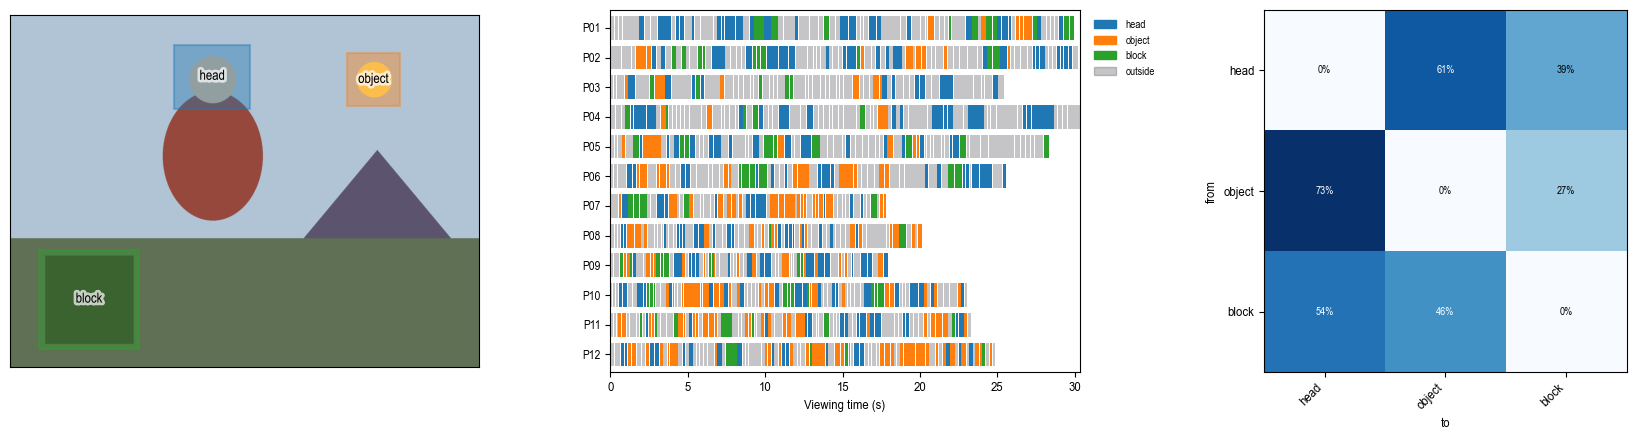

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
fix.show_all_aoi(axes[0])
creapy.show_scarf_plot(axes[1], fix)                                   # one row per participant, coloured by AOI
creapy.show_transition_matrix(axes[2], creapy.transition_matrix(fix))  # where the gaze went after leaving an AOI
fig.tight_layout()
creapy.first_fixation_order(fix)                                       # which AOI was looked at first

## Descriptives, coefficient K and group comparison

In [8]:
df_stats = creapy.participant_table(fix, sac)      # fixations, durations, saccades, scanpath length, spread, K
grouping = {s: ('expert' if s <= 'P06' else 'layperson') for s in fix.subjects}
creapy.group_comparison(df_stats, grouping)          # Welch t / Mann-Whitney for two groups, ANOVA for more

,measure,mean_expert,sd_expert,n_expert,mean_layperson,sd_layperson,n_layperson,test,statistic,p_value,mann_whitney_U,mann_whitney_p
0,n_fixations,88.166667,8.084965,6,88.666667,12.706953,6,Welch t,-0.081319,9.370754e-01,17.5,1.000000
1,viewing_time_s,28.293817,2.305739,6,21.173083,2.981413,6,Welch t,4.627813,1.104305e-03,36.0,0.002165
2,mean_fixation_duration,279.084364,13.598801,6,197.071655,7.155886,6,Welch t,13.073066,1.818644e-06,36.0,0.002165
3,median_fixation_duration,260.441667,20.516248,6,182.358333,6.676407,6,Welch t,8.864993,1.097115e-04,36.0,0.002165
4,total_fixation_duration,24558.116667,1922.300958,6,17454.416667,2428.777141,6,Welch t,5.617665,2.683728e-04,36.0,0.002165
5,scanpath_length_px,33491.601486,2885.202671,6,33274.231617,6238.577767,6,Welch t,0.077464,9.404085e-01,14.0,0.588745
6,mean_x,806.992108,48.791691,6,907.073219,60.163303,6,Welch t,-3.164776,1.059909e-02,2.0,0.008658
7,mean_y,482.996051,50.335849,6,417.751921,37.391305,6,Welch t,2.548713,3.067462e-02,30.0,0.064935
8,spread_px,422.283065,20.545717,6,422.767639,40.451907,6,Welch t,-0.026161,9.798185e-01,22.0,0.588745
9,mean_pupil,899.631554,3.606245,6,849.212289,2.045219,6,Welch t,29.789312,2.060005e-09,36.0,0.002165


The Statistics view's boxplot is `show_group_boxplot`: one measure, one point per participant, any table with a `participant` column (`participant_table`, `participant_rqa`, `aoi_metrics`).

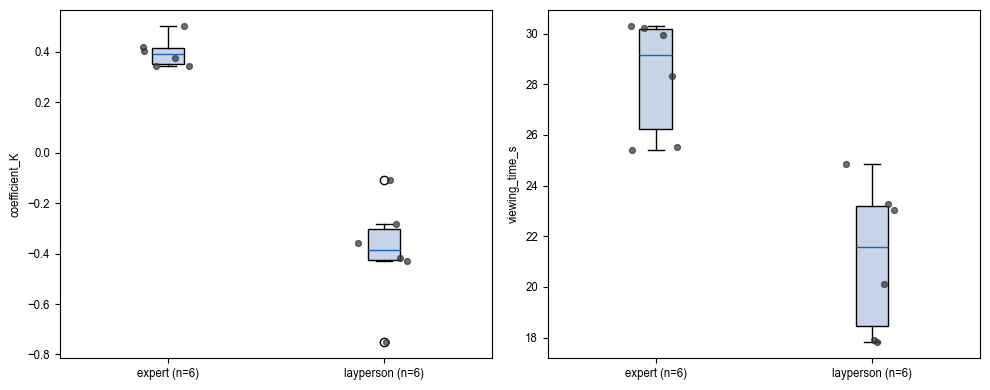

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
creapy.show_group_boxplot(df_stats, 'coefficient_K', grouping, ax=axes[0])
creapy.show_group_boxplot(df_stats, 'mean_fix_dur' if 'mean_fix_dur' in df_stats else df_stats.columns[2], grouping, ax=axes[1])
fig.tight_layout()


Coefficient K (Krejtz et al. 2016) is positive for focal viewing (long fixations, short saccades) and negative
for ambient scanning. The example's 'experts' were simulated as more focal, so K should separate the groups.

## Time series and rhythm

,participant,peak_frequency_hz,peak_period_s,peak_power
0,P01,1.231917,0.811743,0.081415
1,P02,1.471451,0.679601,0.146962
2,P03,0.863480,1.158104,0.118470
3,P04,1.173644,0.852047,0.108514
4,P05,1.757561,0.568970,0.081964


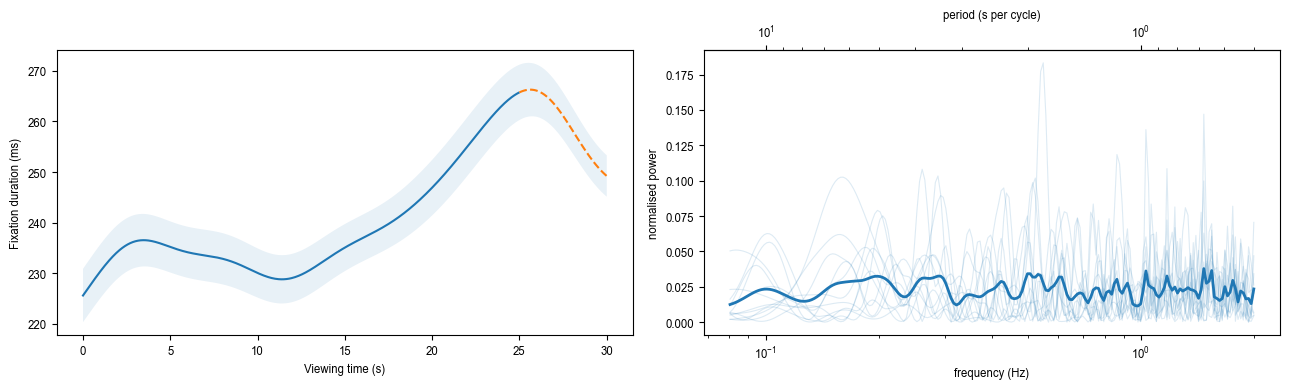

In [10]:
from creapy.stats import participant_periodogram, dominant_period, show_periodogram
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
creapy.show_measure_curve(fix, sac, 'fixation_duration', sigma=2, ax=axes[0])   # smoothed over viewing time; dashed = unreliable tail
df_power = participant_periodogram(fix)                                          # Lomb-Scargle power per participant
show_periodogram(axes[1], df_power)
fig.tight_layout()
dominant_period(df_power).head()


Measures: `'fixation_duration'`, `'saccade_amplitude'`, `'coefficient_k'`, `'pupil'`, `'viewing_distance'` (Tobii glasses). `split_by_group` gives one (fix, sac) pair per group, so a per-group comparison is a loop; the GUI's Time Series view does exactly this.

Coefficient K  (focal ↑ · ambient ↓) - 1061 values aligned with FixationData.df


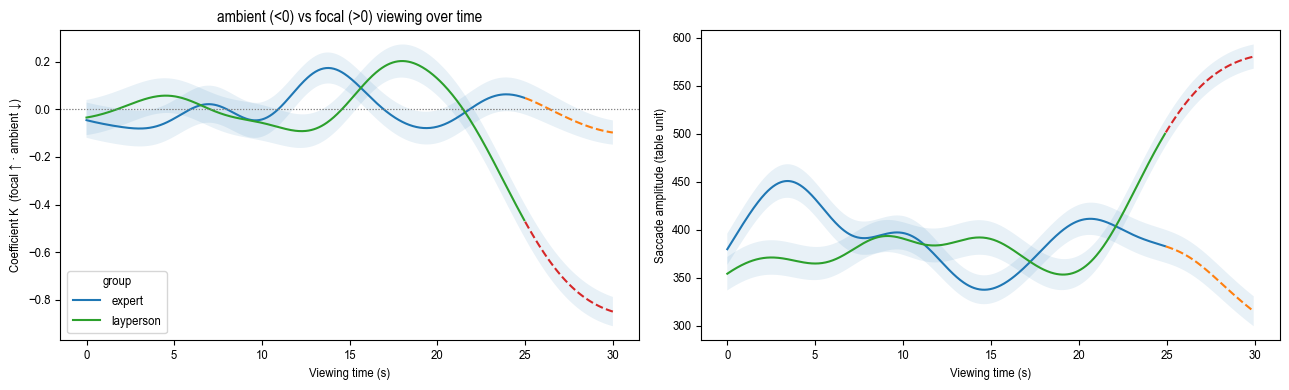

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, fix_g, sac_g in creapy.split_by_group(fix, sac, grouping):
    creapy.show_measure_curve(fix_g, sac_g, 'coefficient_k', sigma=2, ax=axes[0], label=name)
    creapy.show_measure_curve(fix_g, sac_g, 'saccade_amplitude', sigma=2, ax=axes[1], label=name)
axes[0].legend(title="group"); axes[0].set_title("ambient (<0) vs focal (>0) viewing over time")
fig.tight_layout()
# the raw values behind a curve, for your own statistics:
data, values, label = creapy.value_series(fix, sac, 'coefficient_k')
print(label, "-", len(values), "values aligned with", type(data).__name__ + ".df")


## Similarity between viewers: HeatMatch, MultiMatch, ScanMatch, cross-recurrence

{'which': 'scanmatch', 'within_mean': 0.41485373591295965, 'between_mean': 0.39431273362752245, 'observed': 0.020541002285437204, 'p_value': 0.0051994800519948, 'n_permutations': 10000}


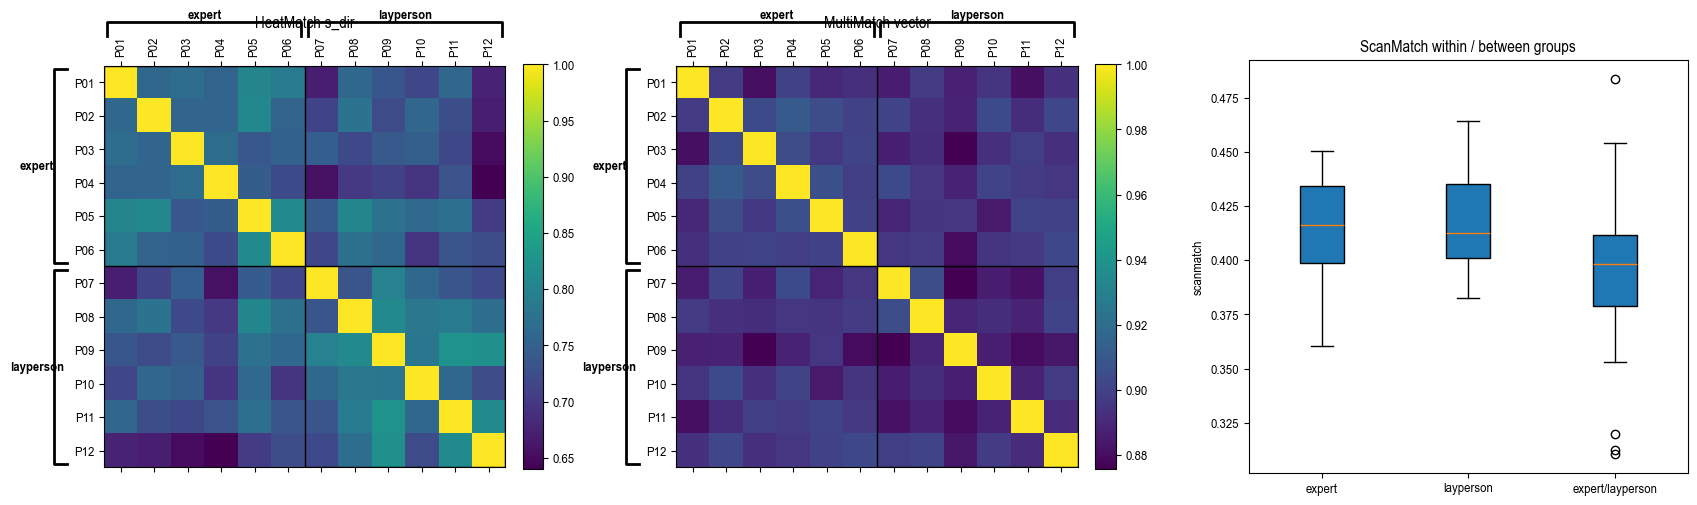

In [12]:
result = sac.compute_heatmatch_similarity(sigma=50, verbose=False)    # HeatMatch (Long et al. 2026)
mm = fix.compute_scanpath_similarity('multimatch', verbose=False)      # five MultiMatch dimensions
sm = fix.compute_scanpath_similarity('scanmatch', verbose=False)
cr = fix.compute_scanpath_similarity('cross_recurrence', verbose=False)
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
result.matshow(which='s_dir', grouping=grouping, ax=axes[0]); axes[0].set_title("HeatMatch s_dir")
mm.matshow(which='mm_vector', grouping=grouping, ax=axes[1]); axes[1].set_title("MultiMatch vector")
sm.show_boxplot(grouping, ax=axes[2]); axes[2].set_title("ScanMatch within / between groups")
fig.tight_layout()
print(sm.permutation_test(grouping, verbose=False))                    # are viewers more alike within their group?

Every result object has the same interface (`matrix`, `matshow`, `show_boxplot`, `permutation_test`, `show_multidimensional_scaling`). `score_overview` averages all pairs, and within / between groups, for every score column, which for MultiMatch gives its five dimensions side by side.

,measure,all pairs,within groups,between groups
0,mm_vector,0.894,0.894,0.894
1,mm_direction,0.668,0.667,0.669
2,mm_length,0.861,0.862,0.859
3,mm_position,0.800,0.802,0.799
4,mm_duration,0.615,0.628,0.605


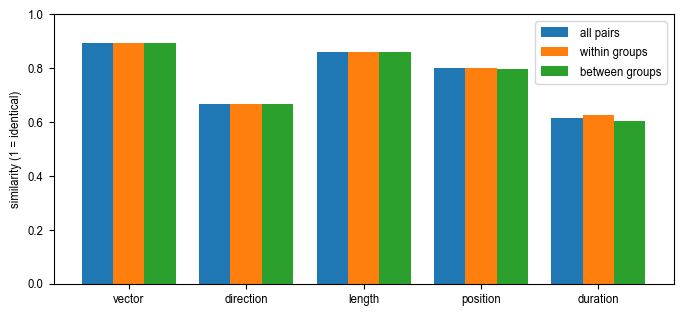

In [13]:
fig, ax = plt.subplots(figsize=(8, 3.5))
mm.show_score_overview(grouping, ax=ax)
mm.score_overview(grouping).round(3)


## Recurrence quantification (Anderson et al. 2013)

,participant,n_fixations,recurrence,determinism,laminarity,corm,n_recurrent_pairs,radius
0,P01,91.0,7.423687,23.026316,41.118421,26.988304,304.0,100.0
1,P02,98.0,8.962760,31.220657,55.046948,30.918155,426.0,100.0
2,P03,76.0,5.333333,17.763158,32.894737,30.350877,152.0,100.0
3,P04,95.0,8.936170,45.363409,59.523810,32.426812,399.0,100.0
4,P05,85.0,6.526611,17.596567,28.969957,27.549561,233.0,100.0


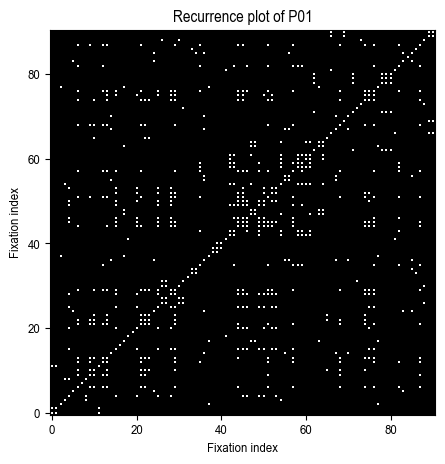

In [14]:
import numpy as np
from creapy.stats import participant_rqa, show_recurrence_plot, default_radius
df_rqa = participant_rqa(fix)                                          # recurrence, determinism, laminarity, corm
subj = fix.subjects[0]
mask = (fix.subj_index == subj).to_numpy()
xy = np.column_stack([fix.fix_x[mask], fix.fix_y[mask]])
fig, ax = plt.subplots(figsize=(5, 5))
show_recurrence_plot(ax, xy, default_radius(fix)); ax.set_title(f"Recurrence plot of {subj}")
df_rqa.head()

## Tobii Pro Lab

```python
df, mapping = creapy.load_fixations("Raum 1 c1 Metrics_Event-based.tsv")   # event-based metrics export
images = creapy.misc.utils.find_images("Final_Fotos für Tobii/c1")          # snapshot name -> file
datasets = creapy.datasets_by_stimulus(df, mapping, stimulus_paths={s: images[s.lower()] for s in df['stimulus'].unique()})

df, mapping = creapy.load_prolab_data_export_chunked("Raum 1 Data export.tsv")   # 70 GB, only the needed columns
df_aoi, info = creapy.load_prolab_aoi_metrics_export("Raum 1 c1 Metrics_AOI-based.tsv")   # dwell/visit totals per AOI
creapy.aoi_metrics_summary(df_aoi, 'Total_duration_of_fixations', by='AOI', group_col='Media')
```

Snapshots of 8000 px are downscaled on loading and the coordinates with them; `FixationData.scale` holds the factor.